In [1]:
!pip install geopandas hdbscan xgboost imbalanced-learn

# Tahap 1 Setup, import library, dan baca data

In [2]:
import os, joblib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import hdbscan
from shapely.geometry import Point
from scipy.stats import randint, uniform, loguniform
from sklearn.neighbors import BallTree
from sklearn.metrics.pairwise import haversine_distances
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, precision_recall_curve,
                             confusion_matrix, roc_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

# ---------------- konfigurasi ----------------
BATAS_TRAIN = "2024-12-31"
RS = 42
STASIUN = {                      # verifikasi koordinat ini dengan data NASA POWER-mu
    "Palangka Raya": (-2.21, 113.92),
    "Sampit":        (-2.53, 112.95),
    "Pangkalan Bun": (-2.68, 111.62),
    "Muara Teweh":   (-0.95, 114.89),
    "Kuala Kapuas":  (-3.00, 114.39),
}
VAR = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

# ---------------- cache ----------------
PAKAI_DRIVE = True      # False kalau tidak mau menyentuh Google Drive (mis. saat dosen menjalankan)
if PAKAI_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = "/content/drive/MyDrive/hotspot_kalteng"
else:
    SAVE_DIR = "/content/cache"
os.makedirs(SAVE_DIR, exist_ok=True)

def cached(nama, fn):
    """Kalau file cache ada -> load; kalau belum -> hitung, simpan, lalu kembalikan."""
    path = f"{SAVE_DIR}/{nama}.joblib"
    if os.path.exists(path):
        print("[cache] load:", nama)
        return joblib.load(path)
    hasil = fn()
    joblib.dump(hasil, path)
    print("[cache] simpan:", nama)
    return hasil

# ---------------- baca data ----------------
df_hotspot = pd.read_csv("/content/hotspot_kalimantan_tengah.csv")
df_meteo   = pd.read_csv("/content/meteorologi_kalimantan_tengah.csv")
batas      = gpd.read_file("/content/Kalimantan Tengah.geojson")
print("Ukuran dataset hotspot:", df_hotspot.shape)
print("Ukuran dataset meteorologi:", df_meteo.shape)

Mounted at /content/drive
Ukuran dataset hotspot: (178732, 15)
Ukuran dataset meteorologi: (10555, 6)


# Tahap 2 Cleaning data meteorologi

In [3]:
# salin dari df_meteo dan ubah kolom tanggal ke datetime
met = df_meteo.copy()
met["tanggal"] = pd.to_datetime(met["tanggal"])

met = met.drop_duplicates(["lokasi", "tanggal"]).sort_values(["lokasi", "tanggal"])

# -999 = missing value NASA POWER
met[VAR] = met[VAR].replace(-999, np.nan)
print("Missing sebelum diisi:\n", met[VAR].isna().sum())

# isi missing dengan interpolasi per stasiun
met[VAR] = met.groupby("lokasi")[VAR].transform(
    lambda s: s.interpolate(limit_direction="both"))
print("Missing sesudah diisi:", met[VAR].isna().sum().sum())

# fitur turunan (rolling per stasiun)
g = met.groupby("lokasi")
met["CH_3d"]  = g["PRECTOTCORR"].transform(lambda s: s.rolling(3,  min_periods=1).sum())
met["CH_7d"]  = g["PRECTOTCORR"].transform(lambda s: s.rolling(7,  min_periods=1).sum())
met["CH_14d"] = g["PRECTOTCORR"].transform(lambda s: s.rolling(14, min_periods=1).sum())
met["RH_7d"]  = g["RH2M"].transform(lambda s: s.rolling(7, min_periods=1).mean())
met["T_7d"]   = g["T2M"].transform(lambda s: s.rolling(7, min_periods=1).mean())

def hari_kering_berturut(s, ambang=1.0):
    kering = s < ambang
    grup = (~kering).cumsum()
    return kering.groupby(grup).cumsum()

met["HKB"] = g["PRECTOTCORR"].transform(hari_kering_berturut)  # hari kering berturut-turut

Missing sebelum diisi:
 T2M            15
RH2M           15
PRECTOTCORR    15
WS10M          15
dtype: int64
Missing sesudah diisi: 0


# Tahap 3 Cleaning data hotspot dan pemotongan batas provinsi

In [4]:
hs = df_hotspot.copy()
hs["acq_date"] = pd.to_datetime(hs["acq_date"])
print("Jumlah awal:", len(hs))

# buang deteksi confidence rendah ('l'); hapus baris ini kalau mau semua dipakai
hs = hs[hs["confidence"].isin(["n", "h"])]
hs = hs.rename(columns={"acq_date": "tanggal"})
hs = hs[["tanggal", "latitude", "longitude"]].dropna().reset_index(drop=True)
print("Setelah filter confidence:", len(hs))

# ---- potong ke batas provinsi ----
batas = batas.to_crs("EPSG:4326")
try:
    batas_union = batas.geometry.union_all()      # geopandas >= 1.0
except AttributeError:
    batas_union = batas.geometry.unary_union      # geopandas lama

gdf_hs = gpd.GeoDataFrame(
    hs.copy(),
    geometry=gpd.points_from_xy(hs["longitude"], hs["latitude"]),
    crs="EPSG:4326",
)
dalam = gdf_hs.geometry.intersects(batas_union)
print("Hotspot dalam provinsi :", dalam.sum())
print("Hotspot di luar        :", (~dalam).sum())

hs = gdf_hs.loc[dalam].drop(columns="geometry").reset_index(drop=True)

# ---- cek posisi stasiun terhadap batas provinsi ----
for nm, (la, lo) in STASIUN.items():
    print(f"{nm:15s} di dalam provinsi: {batas_union.contains(Point(lo, la))}")

Jumlah awal: 178732
Setelah filter confidence: 172288
Hotspot dalam provinsi : 172129
Hotspot di luar        : 159
Palangka Raya   di dalam provinsi: True
Sampit          di dalam provinsi: True
Pangkalan Bun   di dalam provinsi: True
Muara Teweh     di dalam provinsi: True
Kuala Kapuas    di dalam provinsi: True


# Tahap 4 Fungsi pendukung dan parameter awal

In [5]:
MS = 30    # min_samples HDBSCAN

def evaluasi(nama, y, proba, thr=0.5, **extra):
    pred = (np.asarray(proba) >= thr).astype(int)
    d = {"Model": nama,
         "Accuracy":  accuracy_score(y, pred),
         "Precision": precision_score(y, pred, zero_division=0),
         "Recall":    recall_score(y, pred, zero_division=0),
         "F1-score":  f1_score(y, pred, zero_division=0),
         "ROC-AUC":   roc_auc_score(y, proba),
         "PR-AUC":    average_precision_score(y, proba)}
    d.update(extra)
    return d

def thr_optimal(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1s = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.argmax(f1s[:-1])])

# ---------- zonasi ----------
def zona_hdbscan(h, mt, selection="leaf", mcs=150, ms=MS):
    Xtr = np.radians(h.loc[mt, ["latitude", "longitude"]].values)
    Xte = np.radians(h.loc[~mt, ["latitude", "longitude"]].values)
    cl = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms, metric="haversine",
                         cluster_selection_method=selection, prediction_data=True).fit(Xtr)
    lab_te, _ = hdbscan.approximate_predict(cl, Xte)
    return cl.labels_, lab_te

def zona_seragam(fn_zona, R_km=5.0):
    """Titik test -> zona training terdekat dalam R km (aturan penugasan yang seragam)."""
    def f(h, mt, **kw):
        lab_tr, _ = fn_zona(h, mt, **kw)
        Xtr = np.radians(h.loc[mt,  ["latitude", "longitude"]].values)
        Xte = np.radians(h.loc[~mt, ["latitude", "longitude"]].values)
        ok = lab_tr >= 0
        d, idx = BallTree(Xtr[ok], metric="haversine").query(Xte, k=1)
        lab_te = np.where(d[:, 0] * 6371 <= R_km, lab_tr[ok][idx[:, 0]], -1)
        return lab_tr, lab_te
    return f

# ---------- parameter awal (hasil tuning v1, supaya tidak perlu mengulang 50 menit) ----------
RF_PARAMS = {'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 3,
             'min_samples_split': 18, 'n_estimators': 591}
XGB_PARAMS = {'colsample_bytree': 0.908897907718663, 'gamma': 0.0993578407670862,
              'learning_rate': 0.011049202253484457, 'max_depth': 5, 'min_child_weight': 3,
              'n_estimators': 280, 'subsample': 0.88453678109946}

# ---------- model (membaca RF_PARAMS / XGB_PARAMS global saat dipanggil) ----------
def buat_rf(seed=RS, cw=None):
    return RandomForestClassifier(**RF_PARAMS, class_weight=cw, random_state=seed, n_jobs=-1)

def buat_xgb(seed=RS, spw=1.0):
    return XGBClassifier(**XGB_PARAMS, objective="binary:logistic", eval_metric="logloss",
                         scale_pos_weight=spw, tree_method="hist", random_state=seed, n_jobs=-1)

def latih(X, y, skenario="tanpa"):
    if skenario == "class_weight":
        spw = (y == 0).sum() / (y == 1).sum()
        return buat_rf(cw="balanced_subsample").fit(X, y), buat_xgb(spw=spw).fit(X, y)
    return buat_rf().fit(X, y), buat_xgb().fit(X, y)

def proba_ens(rf, xgb, X, w=0.5):
    return w * rf.predict_proba(X)[:, 1] + (1 - w) * xgb.predict_proba(X)[:, 1]

# TAHAP 5 Zonasi spasial HDBSCAN, fitur cuaca tambahan, dan visualisasi peta

In [6]:
from scipy.stats import loguniform

def tambah_fitur_met(m):
    m = m.sort_values(["lokasi", "tanggal"]).copy()
    es = 0.6108 * np.exp(17.27 * m["T2M"] / (m["T2M"] + 237.3))     # tekanan uap jenuh (kPa)
    m["VPD"] = es * (1 - m["RH2M"].clip(0, 100) / 100)
    g = m.groupby("lokasi")
    m["VPD_7d"] = g["VPD"].transform(lambda s: s.rolling(7, min_periods=1).mean())
    m["CH_30d"] = g["PRECTOTCORR"].transform(lambda s: s.rolling(30, min_periods=1).sum())
    m["CH_60d"] = g["PRECTOTCORR"].transform(lambda s: s.rolling(60, min_periods=1).sum())
    m["HKB5"]   = g["PRECTOTCORR"].transform(lambda s: hari_kering_berturut(s, ambang=5.0))
    return m

met2 = tambah_fitur_met(met)

# ---------- zonasi: HDBSCAN eom + penugasan seragam 5 km ----------
ZONASI = dict(selection="eom", mcs=150)      # alternatif: dict(selection="leaf")
R_SERAGAM = 5.0

h = hs[["tanggal", "latitude", "longitude"]].copy()
mt = (h["tanggal"] <= BATAS_TRAIN).values
lab_tr, lab_te = zona_seragam(zona_hdbscan, R_SERAGAM)(h, mt, **ZONASI)
h["zona"] = -1
h.loc[mt, "zona"] = lab_tr
h.loc[~mt, "zona"] = lab_te

htr = h.loc[mt]
htr = htr[htr["zona"] >= 0]
zi = htr.groupby("zona").agg(lat=("latitude", "mean"), lon=("longitude", "mean"))
st_rad = np.radians(np.array(list(STASIUN.values())))
JARAK_ST = haversine_distances(np.radians(zi[["lat", "lon"]].values), st_rad) * 6371   # zona x stasiun
zi["jarak_stasiun_km"] = JARAK_ST.min(axis=1)

print("Zona:", len(zi), "| cakupan test: %.1f%%" % (100 * (lab_te >= 0).mean()))

Zona: 60 | cakupan test: 67.0%


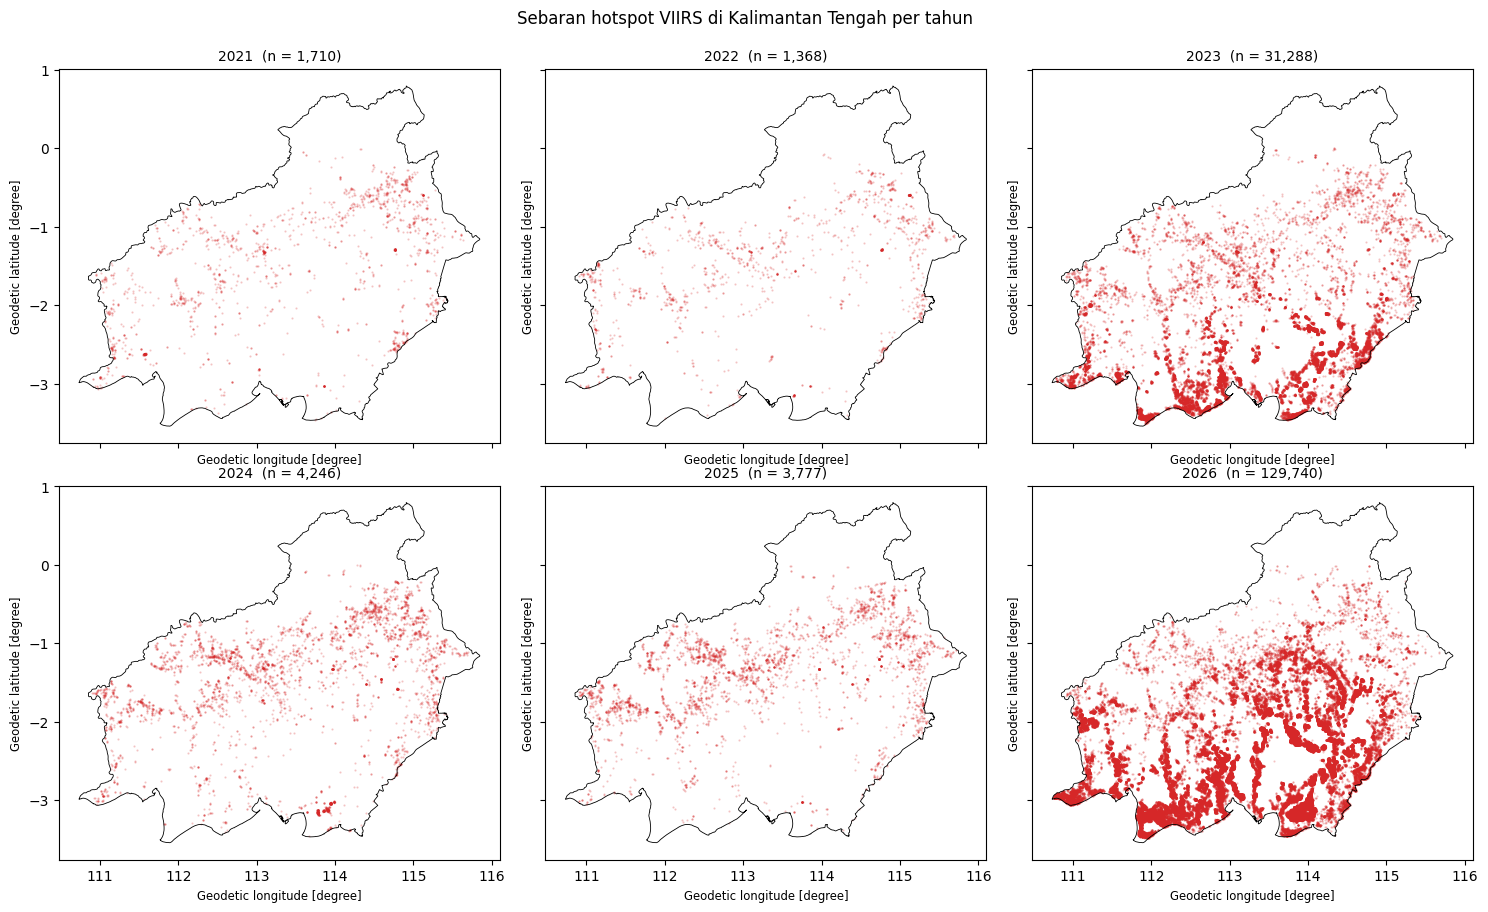

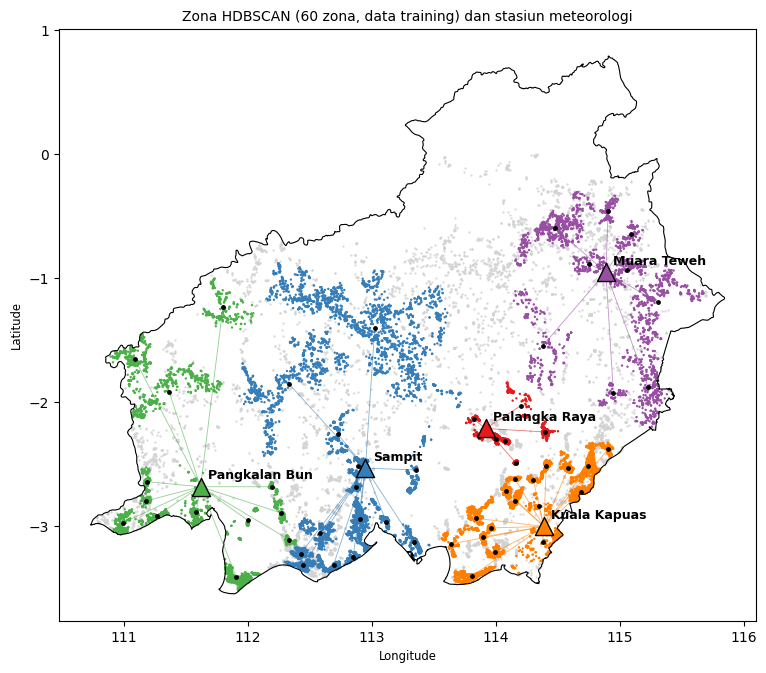

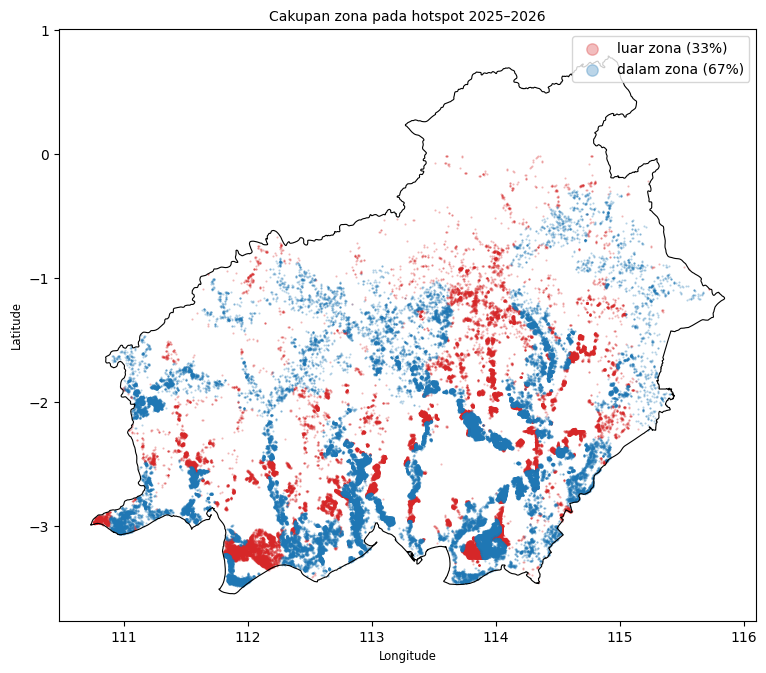

In [7]:
nama_st = list(STASIUN)
zi["stasiun"] = [nama_st[i] for i in JARAK_ST.argmin(axis=1)]
warna_st = dict(zip(nama_st, plt.cm.Set1.colors[:len(nama_st)]))

def dasar(ax, judul):
    batas.boundary.plot(ax=ax, color="k", linewidth=0.8)
    ax.set_title(judul, fontsize=10)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")

# ---------- Peta 1: penyebaran hotspot per tahun ----------
tahun = sorted(hs["tanggal"].dt.year.unique())
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, th in zip(axes.ravel(), tahun):
    d = hs[hs["tanggal"].dt.year == th]
    batas.boundary.plot(ax=ax, color="k", linewidth=0.6)
    ax.scatter(d["longitude"], d["latitude"], s=0.3, alpha=0.25, c="tab:red")
    ax.set_title(f"{th}  (n = {len(d):,})", fontsize=10)
plt.suptitle("Sebaran hotspot VIIRS di Kalimantan Tengah per tahun", y=1.0)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/peta_hotspot_tahunan.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- Peta 2: zona HDBSCAN + stasiun + garis ke stasiun dominan ----------
fig, ax = plt.subplots(figsize=(9, 8))
dasar(ax, f"Zona HDBSCAN ({len(zi)} zona, data training) dan stasiun meteorologi")
ns = h[mt & (h["zona"] == -1).values]
dz = h[mt & (h["zona"] >= 0).values]
ax.scatter(ns["longitude"], ns["latitude"], s=0.3, c="lightgrey", label="noise")
ax.scatter(dz["longitude"], dz["latitude"], s=0.5,
           c=[warna_st[s] for s in dz["zona"].map(zi["stasiun"])])
for z, r in zi.iterrows():
    la, lo = STASIUN[r["stasiun"]]
    ax.plot([r["lon"], lo], [r["lat"], la], color=warna_st[r["stasiun"]], lw=0.6, alpha=0.6)
ax.scatter(zi["lon"], zi["lat"], s=6, c="k", zorder=4)
for nm, (la, lo) in STASIUN.items():
    ax.scatter(lo, la, marker="^", s=170, c=[warna_st[nm]], edgecolor="k", zorder=5)
    ax.text(lo + 0.06, la + 0.06, nm, fontsize=9, weight="bold")
plt.savefig(f"{SAVE_DIR}/peta_zona_stasiun.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- Peta 3: cakupan zona pada data test (titik di dalam zona vs noise) ----------
ht = h[~mt]
fig, ax = plt.subplots(figsize=(9, 8))
dasar(ax, "Cakupan zona pada hotspot 2025–2026")
a = ht[ht["zona"] == -1]; b = ht[ht["zona"] >= 0]
ax.scatter(a["longitude"], a["latitude"], s=0.3, alpha=0.3, c="tab:red", label=f"luar zona ({100*len(a)/len(ht):.0f}%)")
ax.scatter(b["longitude"], b["latitude"], s=0.3, alpha=0.3, c="tab:blue", label=f"dalam zona ({100*len(b)/len(ht):.0f}%)")
ax.legend(markerscale=15)
plt.savefig(f"{SAVE_DIR}/peta_cakupan_test.png", dpi=200, bbox_inches="tight")
plt.show()

# TAHAP 6 Panel zona-hari, target H+1, daftar fitur, dan split berbasis waktu

In [8]:
FITUR_MET = VAR + ["CH_3d", "CH_7d", "CH_14d", "CH_30d", "CH_60d",
                   "RH_7d", "T_7d", "HKB", "HKB5", "VPD", "VPD_7d"]

def bangun_panel_v2(h, zi, jarak_st, met2, r_tetangga=30.0, p_idw=2.0):
    dates = pd.date_range(met2["tanggal"].min(), met2["tanggal"].max())
    zones = zi.index.values
    D, Z = len(dates), len(zones)
    feats = {}

    def bcast(v):       # vektor per tanggal -> matriks D x Z
        return pd.DataFrame(np.repeat(np.asarray(v)[:, None], Z, axis=1), index=dates, columns=zones)

    # --- riwayat hotspot per zona
    cnt = (h[h["zona"] >= 0].groupby(["tanggal", "zona"]).size()
           .unstack(fill_value=0).reindex(index=dates, columns=zones, fill_value=0))
    Hb = (cnt > 0).astype(float)
    feats["hs_hari_ini"] = Hb
    feats["n_hs_log"] = np.log1p(cnt)
    for w in (3, 7, 14, 30):
        feats[f"hs_{w}d"] = Hb.rolling(w, min_periods=1).sum()
    idx = np.arange(D)[:, None]
    last = pd.DataFrame(np.where(Hb.values > 0, idx, np.nan), index=dates, columns=zones).ffill()
    feats["hari_sejak_hs"] = pd.DataFrame(idx - last.values, index=dates, columns=zones).fillna(90).clip(upper=90)

    # --- tetangga (radius r_tetangga km) dan aktivitas provinsi
    dz = haversine_distances(np.radians(zi[["lat", "lon"]].values)) * 6371
    A = ((dz <= r_tetangga) & (dz > 0)).astype(float)
    nb = pd.DataFrame((Hb.values @ A.T) / np.maximum(A.sum(axis=1), 1.0), index=dates, columns=zones)
    feats["nb_hari_ini"] = nb
    feats["nb_7d"] = nb.rolling(7, min_periods=1).mean()
    prov = Hb.mean(axis=1)
    feats["prov_aktif"] = bcast(prov.values)
    feats["prov_aktif_7d"] = bcast(prov.rolling(7, min_periods=1).mean().values)

    # --- cuaca: IDW dari stasiun ke titik pusat zona
    nama_st = list(STASIUN)
    Wt = 1.0 / np.maximum(jarak_st, 1.0) ** p_idw
    Wt = Wt / Wt.sum(axis=1, keepdims=True)                      # zona x stasiun
    for f in FITUR_MET:
        M = (met2.pivot(index="tanggal", columns="lokasi", values=f)
                  .reindex(index=dates, columns=nama_st).interpolate(limit_direction="both"))
        feats[f] = pd.DataFrame(M.values @ Wt.T, index=dates, columns=zones)

    # --- musim
    doy = dates.dayofyear.values
    feats["musim_sin"] = bcast(np.sin(2 * np.pi * doy / 365.25))
    feats["musim_cos"] = bcast(np.cos(2 * np.pi * doy / 365.25))

    # --- rakit (urutan: per tanggal, lalu per zona)
    data = {"tanggal": np.repeat(dates.values, Z), "zona": np.tile(zones, D),
            "target": Hb.shift(-1).values.ravel()}
    for k, v in feats.items():
        data[k] = v.values.ravel()
    for k in ("lat", "lon", "jarak_stasiun_km"):
        data[k] = np.tile(zi[k].values, D)
    pn = pd.DataFrame(data).dropna(subset=["target"])
    pn["target"] = pn["target"].astype(int)
    return pn.reset_index(drop=True)

pn = bangun_panel_v2(h, zi, JARAK_ST, met2)
print(pn.shape, "| positif: %.2f%%" % (100 * pn["target"].mean()))

# ---------- kelompok fitur ----------
F_A = VAR + ["CH_3d", "CH_7d", "CH_14d", "RH_7d", "T_7d", "HKB"] + \
      ["lat", "lon", "jarak_stasiun_km", "hs_hari_ini", "hs_7d"]       # setara fitur lama, tanpa n_hist
F_CUACA = ["CH_30d", "CH_60d", "HKB5", "VPD", "VPD_7d"]
F_HS    = ["n_hs_log", "hs_3d", "hs_14d", "hs_30d", "hari_sejak_hs"]
F_NB    = ["nb_hari_ini", "nb_7d", "prov_aktif", "prov_aktif_7d"]
F_MUSIM = ["musim_sin", "musim_cos"]
FITUR_ALL = F_A + F_CUACA + F_HS + F_NB + F_MUSIM

# ---------- split: 2024-12-31 dibuang dari train (targetnya jatuh di 2025) ----------
T0 = pd.Timestamp(BATAS_TRAIN)
tr_full = pn[pn["tanggal"] < T0].reset_index(drop=True)
te      = pn[pn["tanggal"] > T0].reset_index(drop=True)
X_full, y_full = tr_full[FITUR_ALL], tr_full["target"]

# CV per tahun: fold 1 validasi 2023 (tahun api), fold 2 validasi 2024
yr = tr_full["tanggal"].dt.year.values
folds = [(np.where(yr <= 2022)[0], np.where(yr == 2023)[0]),
         (np.where(yr <= 2023)[0], np.where(yr == 2024)[0])]

(126600, 34) | positif: 6.75%


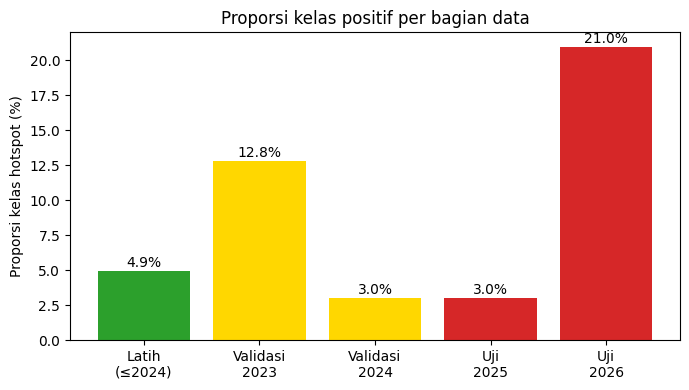

{'Latih\n(≤2024)': 4.92351598173516, 'Validasi\n2023': 12.817351598173515, 'Validasi\n2024': 3.0228310502283104, 'Uji\n2025': 3.0273972602739727, 'Uji\n2026': 20.96244131455399}


In [17]:
def pct(y): return 100 * float(np.mean(y))
data = {"Latih\n(≤2024)": pct(y_full),
        "Validasi\n2023": pct(y_full.iloc[folds[0][1]]),
        "Validasi\n2024": pct(y_full.iloc[folds[1][1]]),
        "Uji\n2025": pct(te.loc[te["tanggal"].dt.year == 2025, "target"]),
        "Uji\n2026": pct(te.loc[te["tanggal"].dt.year == 2026, "target"])}
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(data.keys(), data.values(), color=["tab:green", "gold", "gold", "tab:red", "tab:red"])
for b, v in zip(bars, data.values()):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f}%", ha="center")
ax.set_ylabel("Proporsi kelas hotspot (%)"); ax.set_title("Proporsi kelas positif per bagian data")
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/proporsi_kelas.png", dpi=200); plt.show()
print(data)

In [10]:
FITUR_PAKAI = FITUR_ALL     # ganti setelah melihat hasil ablasi (Blok D)
F = FITUR_PAKAI

In [19]:
# ---- contoh data untuk slide: satu baris = satu zona pada satu hari ----
kolom_contoh = ["zona", "tanggal", "T2M", "RH2M", "PRECTOTCORR", "CH_7d", "HKB",
                "hs_hari_ini", "hs_7d", "target"]

# ambil tanggal puncak musim api 2023 supaya ada contoh target 1 dan 0 sekaligus
contoh = pn[pn["tanggal"] == "2023-09-15"][kolom_contoh].round(2)
print("Contoh dengan target = 1:")
print(contoh[contoh["target"] == 1].head(5).to_string(index=False))
print("\nContoh dengan target = 0:")
print(contoh[contoh["target"] == 0].head(5).to_string(index=False))

Contoh dengan target = 1:
 zona    tanggal   T2M  RH2M  PRECTOTCORR  CH_7d  HKB  hs_hari_ini  hs_7d  target
    2 2023-09-15 27.88 74.56         0.75   2.09 6.97          1.0    4.0       1
   15 2023-09-15 27.93 74.52         0.53   2.14 6.65          1.0    7.0       1
   31 2023-09-15 28.43 71.83         0.18   1.25 6.70          0.0    6.0       1
   35 2023-09-15 27.62 77.06         0.14   2.46 4.67          1.0    7.0       1
   39 2023-09-15 27.56 77.61         0.13   2.21 4.89          1.0    7.0       1

Contoh dengan target = 0:
 zona    tanggal   T2M  RH2M  PRECTOTCORR  CH_7d  HKB  hs_hari_ini  hs_7d  target
    0 2023-09-15 27.94 74.33         0.62   2.04 6.83          1.0    5.0       0
    1 2023-09-15 27.84 75.11         0.50   2.55 6.53          0.0    3.0       0
    3 2023-09-15 27.87 74.79         0.57   2.32 6.69          0.0    2.0       0
    4 2023-09-15 28.17 73.72         0.15   1.29 6.59          0.0    4.0       0
    5 2023-09-15 27.87 74.71         0.64   2

# TAHAP 7 Ablasi kelompok fitur

In [11]:
def cv_tahun(cols):
    skor = []
    for tr, va in folds:
        rf, xgb = latih(X_full.iloc[tr][cols], y_full.iloc[tr], "tanpa")
        p = proba_ens(rf, xgb, X_full.iloc[va][cols])
        skor.append(average_precision_score(y_full.iloc[va], p))
    return skor

GRUP = {"A. setara fitur lama":              F_A,
        "B. + cuaca baru (VPD, hujan 30/60d)": F_A + F_CUACA,
        "C. + riwayat hotspot kaya":         F_A + F_CUACA + F_HS,
        "D. + tetangga dan provinsi":        F_A + F_CUACA + F_HS + F_NB,
        "E. + musim":                        FITUR_ALL}

def jalankan_ablasi():
    rows = []
    for nm, cols in GRUP.items():
        s = cv_tahun(cols)
        rows.append({"Kelompok": nm, "PR-AUC val 2023": s[0], "PR-AUC val 2024": s[1],
                     "Rata-rata": np.mean(s)})
    return pd.DataFrame(rows).set_index("Kelompok")

abl = cached("ablasi_fitur_v2", jalankan_ablasi)
print(abl.round(4))

[cache] load: ablasi_fitur_v2
                                     PR-AUC val 2023  PR-AUC val 2024  \
Kelompok                                                                
A. setara fitur lama                          0.6115           0.3525   
B. + cuaca baru (VPD, hujan 30/60d)           0.6427           0.3436   
C. + riwayat hotspot kaya                     0.6749           0.3844   
D. + tetangga dan provinsi                    0.6700           0.3921   
E. + musim                                    0.6759           0.3888   

                                     Rata-rata  
Kelompok                                        
A. setara fitur lama                    0.4820  
B. + cuaca baru (VPD, hujan 30/60d)     0.4931  
C. + riwayat hotspot kaya               0.5297  
D. + tetangga dan provinsi              0.5311  
E. + musim                              0.5324  


# TAHAP 8 Hyperparameter tuning RF dan XGBoost (RandomizedSearchCV)

In [12]:
rf_param2 = {"n_estimators": randint(150, 400), "max_depth": randint(3, 16),
             "min_samples_split": randint(2, 30), "min_samples_leaf": randint(1, 20),
             "max_features": ["sqrt", 0.3, 0.5], "max_samples": [0.3, 0.5, 0.8]}
xgb_param2 = {"n_estimators": randint(100, 500), "max_depth": randint(2, 8),
              "learning_rate": loguniform(0.005, 0.1), "subsample": uniform(0.6, 0.4),
              "colsample_bytree": uniform(0.5, 0.5), "min_child_weight": randint(1, 20),
              "gamma": uniform(0, 1), "reg_lambda": loguniform(0.5, 20)}

def jalankan_tuning():
    rf_s = RandomizedSearchCV(RandomForestClassifier(random_state=RS, n_jobs=1),
                              rf_param2, n_iter=15, cv=folds, scoring="average_precision",
                              random_state=RS, n_jobs=-1, verbose=1)
    rf_s.fit(X_full[FITUR_PAKAI], y_full)
    xgb_s = RandomizedSearchCV(XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                                             tree_method="hist", random_state=RS, n_jobs=1),
                               xgb_param2, n_iter=15, cv=folds, scoring="average_precision",
                               random_state=RS, n_jobs=-1, verbose=1)
    xgb_s.fit(X_full[FITUR_PAKAI], y_full)
    return {"RF_PARAMS": rf_s.best_params_, "XGB_PARAMS": xgb_s.best_params_,
            "rf_skor": rf_s.best_score_, "xgb_skor": xgb_s.best_score_}

PARAM_V2 = {'RF_PARAMS': {'max_depth': 9, 'max_features': 'sqrt', 'max_samples': 0.8, 'min_samples_leaf': 5, 'min_samples_split': 20, 'n_estimators': 284}, 'XGB_PARAMS': {'colsample_bytree': 0.569746930326021, 'gamma': 0.29214464853521815, 'learning_rate': 0.014983654548550792, 'max_depth': 7, 'min_child_weight': 15, 'n_estimators': 150, 'reg_lambda': 2.0497318936355757, 'subsample': 0.9932923543227152}}

if PARAM_V2 is not None:
    tun2 = PARAM_V2                                  # cepat, tanpa tuning
else:
    tun2 = cached("tuning_v2", jalankan_tuning)      # tuning (di-cache)

RF_PARAMS, XGB_PARAMS = tun2["RF_PARAMS"], tun2["XGB_PARAMS"]

def bersih(d):
    return {k: (float(v) if isinstance(v, (float, np.floating)) else
                int(v) if isinstance(v, (int, np.integer)) else v) for k, v in d.items()}
print("PARAM_V2 =", {"RF_PARAMS": bersih(RF_PARAMS), "XGB_PARAMS": bersih(XGB_PARAMS)})

PARAM_V2 = {'RF_PARAMS': {'max_depth': 9, 'max_features': 'sqrt', 'max_samples': 0.8, 'min_samples_leaf': 5, 'min_samples_split': 20, 'n_estimators': 284}, 'XGB_PARAMS': {'colsample_bytree': 0.569746930326021, 'gamma': 0.29214464853521815, 'learning_rate': 0.014983654548550792, 'max_depth': 7, 'min_child_weight': 15, 'n_estimators': 150, 'reg_lambda': 2.0497318936355757, 'subsample': 0.9932923543227152}}


# TAHAP 9 Penanganan imbalance data (class weight dan undersampling)

In [13]:
# ================= TAHAP 9 v2: Penanganan imbalance (tanpa SMOTE) =================
# [UNDERSAMPLING]: Ini adalah definisi kelas untuk skenario Undersampling.
# Menggunakan teknik UnderBagging (membuat K model dari sampel kelas negatif yang di-downsample).
class UnderBagging:
    """K model, masing-masing dilatih pada subset negatif acak; probabilitas dirata-rakakan."""
    def __init__(self, buat_model, K=10, rasio=1.0, seed=RS):
        self.buat_model, self.K, self.rasio, self.seed = buat_model, K, rasio, seed
    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        yv = np.asarray(y)
        pos, neg = np.where(yv == 1)[0], np.where(yv == 0)[0]
        n_neg = min(len(neg), int(len(pos) * self.rasio))
        self.models_ = []
        for k in range(self.K):
            idx = np.concatenate([pos, rng.choice(neg, n_neg, replace=False)])
            self.models_.append(self.buat_model(k).fit(X.iloc[idx], yv[idx]))
        return self
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.models_], axis=0)
        return np.column_stack([1 - p, p])
    @property
    def feature_importances_(self):
        return np.mean([m.feature_importances_ for m in self.models_], axis=0)

K_UNDER = 10

# [BOBOT CLASS WEIGHT / TANPA]: Fungsi pembantu untuk membuat model Random Forest.
# Parameter 'cw' akan diisi jika menggunakan class_weight, dan bernilai None jika 'tanpa'.
def buat_rf(seed=RS, cw=None, n_est=None):
    p = dict(RF_PARAMS)
    if n_est: p["n_estimators"] = n_est
    return RandomForestClassifier(**p, class_weight=cw, random_state=seed, n_jobs=-1)

# [BOBOT CLASS WEIGHT / TANPA]: Fungsi pembantu untuk membuat model XGBoost.
# Parameter 'spw' (scale_pos_weight) akan diisi jika menggunakan class_weight, dan bernilai 1.0 jika 'tanpa'.
def buat_xgb(seed=RS, spw=1.0):
    return XGBClassifier(**XGB_PARAMS, objective="binary:logistic", eval_metric="logloss",
                         scale_pos_weight=spw, tree_method="hist", random_state=seed, n_jobs=-1)

# PENGATURAN SKENARIO UTAMA
def latih(X, y, skenario="tanpa"):
    # -------------------------------------------------------------------------
    # 1. SKENARIO "TANPA" (Baseline / Tanpa Penanganan Imbalance)
    # Model berjalan apa adanya menggunakan hyperparameter standar hasil tuning.
    # -------------------------------------------------------------------------
    if skenario == "tanpa":
        return buat_rf().fit(X, y), buat_xgb().fit(X, y)

    # -------------------------------------------------------------------------
    # 2. SKENARIO "CLASS_WEIGHT" (Penanganan Menggunakan Bobot Kelas)
    # RF menggunakan penyeimbang internal "balanced_subsample".
    # XGB menggunakan rumus rasio jumlah kelas negatif dibagi kelas positif (spw).
    # -------------------------------------------------------------------------
    if skenario == "class_weight":
        spw = (y == 0).sum() / (y == 1).sum()
        return buat_rf(cw="balanced_subsample").fit(X, y), buat_xgb(spw=spw).fit(X, y)

    # -------------------------------------------------------------------------
    # 3. SKENARIO "UNDERSAMPLING" (Penanganan Menggunakan Undersampling)
    # Model dilatih menggunakan kelas UnderBagging yang didefinisikan di atas.
    # -------------------------------------------------------------------------
    if skenario == "undersampling":
        n_rf = max(50, RF_PARAMS["n_estimators"] // K_UNDER)
        rf = UnderBagging(lambda k: buat_rf(RS + k, n_est=n_rf), K=K_UNDER).fit(X, y)
        xgb = UnderBagging(lambda k: buat_xgb(RS + k), K=K_UNDER).fit(X, y)
        return rf, xgb

# Ketiga skenario di atas dimasukkan ke dalam list untuk diuji secara bergantian (Looping)
SKENARIO = ["tanpa", "class_weight", "undersampling"]
MODEL = ["RF", "XGB", "Soft Voting"]

def jalankan_imbalance():
    Xte_, yte_ = te[F], te["target"]
    cv_rows, test_rows = [], []
    for sk in SKENARIO:
        oof_p = {m: [] for m in MODEL}; oof_y = []; skor = {m: [] for m in MODEL}
        for tr, va in folds:
            rf, xgb = latih(X_full.iloc[tr][F], y_full.iloc[tr], sk)
            Xv_, yv_ = X_full.iloc[va][F], y_full.iloc[va]
            ps = {"RF": rf.predict_proba(Xv_)[:, 1], "XGB": xgb.predict_proba(Xv_)[:, 1],
                  "Soft Voting": proba_ens(rf, xgb, Xv_)}
            for m in MODEL:
                oof_p[m].append(ps[m]); skor[m].append(average_precision_score(yv_, ps[m]))
            oof_y.append(yv_.values)
        oof_y = np.concatenate(oof_y)
        thr = {m: thr_optimal(oof_y, np.concatenate(oof_p[m])) for m in MODEL}
        for m in MODEL:
            cv_rows.append({"Skenario": sk, "Model": m, "PR-AUC val 2023": skor[m][0],
                            "PR-AUC val 2024": skor[m][1], "Rata-rata": np.mean(skor[m])})
        # laporan test (HANYA pelaporan, tidak dipakai untuk memilih)
        rf, xgb = latih(X_full[F], y_full, sk)
        pt = {"RF": rf.predict_proba(Xte_)[:, 1], "XGB": xgb.predict_proba(Xte_)[:, 1],
              "Soft Voting": proba_ens(rf, xgb, Xte_)}
        for m in MODEL:
            test_rows.append(evaluasi(m, yte_, pt[m], thr=thr[m], Skenario=sk, Threshold=round(thr[m], 3)))
    return {"cv": pd.DataFrame(cv_rows).set_index(["Skenario", "Model"]),
            "test": pd.DataFrame(test_rows).set_index(["Skenario", "Model"])}

imb = cached("imbalance_v2", jalankan_imbalance)
print("Seleksi (CV per tahun, PR-AUC):"); print(imb["cv"].round(4))
print("\nLaporan di test (threshold dari OOF tiap skenario):"); print(imb["test"].round(4))

# aturan seleksi (ditetapkan sebelum melihat hasil): skenario dengan PR-AUC CV tertinggi pada
# Soft Voting, kecuali selisihnya dari 'tanpa' < 0.01 -> pilih yang paling sederhana ('tanpa')
sv = imb["cv"].xs("Soft Voting", level="Model")["Rata-rata"]
SK_TERBAIK = sv.idxmax()
if sv.max() - sv["tanpa"] < 0.01:
    SK_TERBAIK = "tanpa"
print("\nSkenario terpilih:", SK_TERBAIK)

[cache] load: imbalance_v2
Seleksi (CV per tahun, PR-AUC):
                           PR-AUC val 2023  PR-AUC val 2024  Rata-rata
Skenario      Model                                                   
tanpa         RF                    0.7000           0.3847     0.5423
              XGB                   0.6455           0.3928     0.5191
              Soft Voting           0.6814           0.3901     0.5357
class_weight  RF                    0.1719           0.3700     0.2710
              XGB                   0.4550           0.3890     0.4220
              Soft Voting           0.2972           0.3788     0.3380
undersampling RF                    0.4578           0.3782     0.4180
              XGB                   0.5220           0.3903     0.4562
              Soft Voting           0.4900           0.3848     0.4374

Laporan di test (threshold dari OOF tiap skenario):
                           Accuracy  Precision  Recall  F1-score  ROC-AUC  \
Skenario      Model           

# TAHAP 10 Model final: baseline, soft voting, threshold, dan evaluasi test (Tabel A, B, C)

Threshold (OOF): {'RF': 0.257, 'XGB': 0.152, 'Soft Voting': 0.21}

Tabel A: threshold 0.5 (baseline -> tuned)
                      Accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC
Model                                                                       
Persistence             0.9357     0.7062  0.6994    0.7028   0.8320  0.5266
RF baseline             0.9290     0.7685  0.4970    0.6037   0.9511  0.7199
XGB baseline            0.9395     0.7922  0.6021    0.6842   0.9539  0.7760
Soft Voting baseline    0.9393     0.8001  0.5896    0.6789   0.9581  0.7804
RF tuned                0.9449     0.8384  0.6113    0.7071   0.9598  0.7897
XGB tuned               0.9402     0.8715  0.5285    0.6579   0.9619  0.8011
Soft Voting tuned       0.9433     0.8585  0.5731    0.6873   0.9612  0.7984

Tabel B: model final (threshold dari OOF)
                   Accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC  \
Model                                                                       


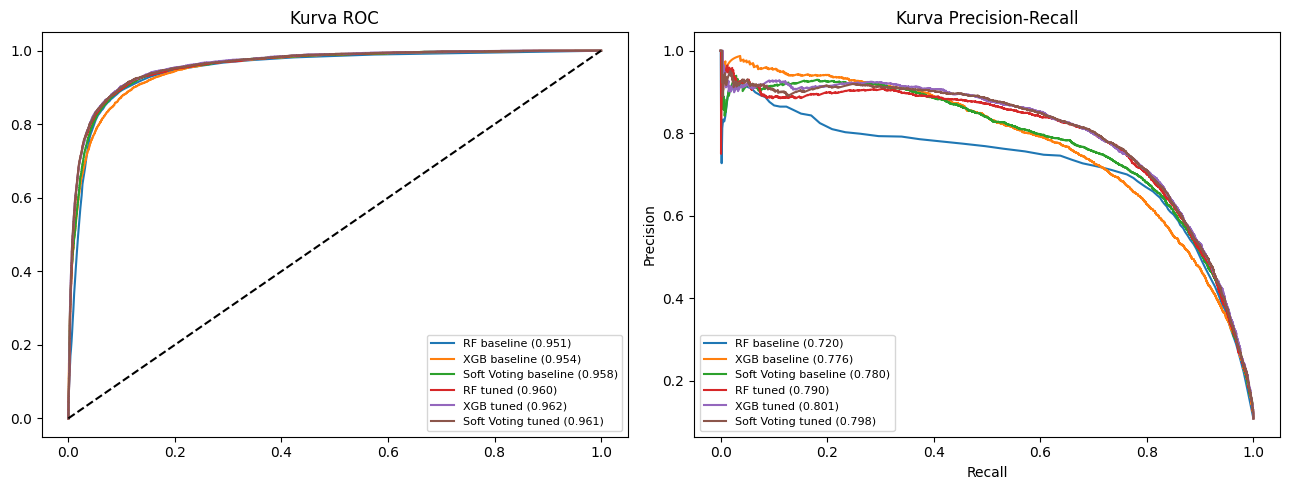

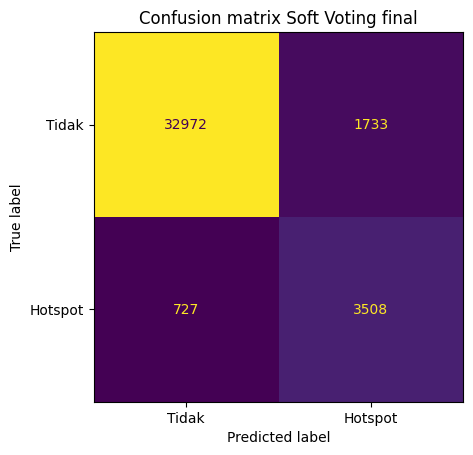

In [14]:
# ================= Tahap 10 : threshold OOF, model final, tabel perbandingan =================
F = FITUR_PAKAI
Xt, yt = te[F], te["target"]
p_pers = te["hs_hari_ini"].values               # persistence: besok = hari ini

# ---------- 1) threshold dari prediksi out-of-fold (validasi 2023 + 2024) ----------
oof_p = {m: [] for m in MODEL}; oof_y = []
for tr, va in folds:
    rf, xgb = latih(X_full.iloc[tr][F], y_full.iloc[tr], SK_TERBAIK)
    Xv_ = X_full.iloc[va][F]
    oof_p["RF"].append(rf.predict_proba(Xv_)[:, 1])
    oof_p["XGB"].append(xgb.predict_proba(Xv_)[:, 1])
    oof_p["Soft Voting"].append(proba_ens(rf, xgb, Xv_))
    oof_y.append(y_full.iloc[va].values)
oof_y = np.concatenate(oof_y)
THR = {m: thr_optimal(oof_y, np.concatenate(oof_p[m])) for m in MODEL}
print("Threshold (OOF):", {k: round(v, 3) for k, v in THR.items()})

# ---------- 2) model final: latih pada seluruh train, prediksi test ----------
rf_f, xgb_f = latih(X_full[F], y_full, SK_TERBAIK)
P = {"RF": rf_f.predict_proba(Xt)[:, 1], "XGB": xgb_f.predict_proba(Xt)[:, 1]}
P["Soft Voting"] = proba_ens(rf_f, xgb_f, Xt)

# ---------- 3) baseline: parameter default, tanpa tuning, fitur yang sama ----------
rf0 = RandomForestClassifier(random_state=RS, n_jobs=-1).fit(X_full[F], y_full)
xgb0 = XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                     tree_method="hist", random_state=RS, n_jobs=-1).fit(X_full[F], y_full)
p0 = {"RF": rf0.predict_proba(Xt)[:, 1], "XGB": xgb0.predict_proba(Xt)[:, 1]}
p0["Soft Voting"] = 0.5 * p0["RF"] + 0.5 * p0["XGB"]

# ---------- 4) Tabel A: tangga baseline -> tuned (threshold 0.5, apple to apple) ----------
tabelA = pd.DataFrame(
    [evaluasi("Persistence", yt, p_pers)] +
    [evaluasi(f"{m} baseline", yt, p0[m]) for m in MODEL] +
    [evaluasi(f"{m} tuned", yt, P[m]) for m in MODEL]
).set_index("Model").round(4)
print("\nTabel A: threshold 0.5 (baseline -> tuned)")
print(tabelA)

# ---------- 5) Tabel B: model final dengan threshold dari validasi ----------
tabelB = pd.DataFrame(
    [evaluasi("Persistence", yt, p_pers)] +
    [evaluasi(f"{m} final", yt, P[m], thr=THR[m], Threshold=round(THR[m], 3)) for m in MODEL]
).set_index("Model").round(4)
print("\nTabel B: model final (threshold dari OOF)")
print(tabelB)

f1_pers = f1_score(yt, p_pers, zero_division=0)
for m in MODEL:
    f1_m = tabelB.loc[f"{m} final", "F1-score"]
    print(f"Selisih F1 {m} vs persistence: {f1_m - f1_pers:+.4f}")

# ---------- 6) performa per tahun (model final Soft Voting vs persistence) ----------
d = te[["tanggal", "target"]].copy()
d["p"] = P["Soft Voting"]; d["pers"] = p_pers
rows = []
for th, g in d.groupby(d["tanggal"].dt.year):
    pr_ = (g["p"] >= THR["Soft Voting"]).astype(int)
    f1_m = f1_score(g["target"], pr_, zero_division=0)
    f1_p = f1_score(g["target"], g["pers"], zero_division=0)
    rows.append({"Tahun": th, "n_positif": int(g["target"].sum()), "rasio_positif": g["target"].mean(),
                 "PR-AUC": average_precision_score(g["target"], g["p"]),
                 "Precision": precision_score(g["target"], pr_, zero_division=0),
                 "Recall": recall_score(g["target"], pr_, zero_division=0),
                 "F1": f1_m, "F1 persistence": f1_p, "Selisih F1": f1_m - f1_p})
tabelC = pd.DataFrame(rows).set_index("Tahun").round(4)
print("\nTabel C: per tahun")
print(tabelC)

# ---------- 7) grafik: ROC, Precision-Recall, confusion matrix ----------
kurva = {"RF baseline": p0["RF"], "XGB baseline": p0["XGB"], "Soft Voting baseline": p0["Soft Voting"],
         "RF tuned": P["RF"], "XGB tuned": P["XGB"], "Soft Voting tuned": P["Soft Voting"]}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nm, p in kurva.items():
    fpr, tpr, _ = roc_curve(yt, p)
    ax[0].plot(fpr, tpr, label=f"{nm} ({roc_auc_score(yt, p):.3f})")
    pr, rc, _ = precision_recall_curve(yt, p)
    ax[1].plot(rc, pr, label=f"{nm} ({average_precision_score(yt, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("Kurva ROC"); ax[0].legend(fontsize=8)
ax[1].set_title("Kurva Precision-Recall"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/kurva_roc_pr.png", dpi=200); plt.show()

ConfusionMatrixDisplay(confusion_matrix(yt, (P["Soft Voting"] >= THR["Soft Voting"]).astype(int)),
                       display_labels=["Tidak", "Hotspot"]).plot(colorbar=False)
plt.title("Confusion matrix Soft Voting final")
plt.savefig(f"{SAVE_DIR}/confusion_matrix.png", dpi=200); plt.show()

# ---------- 8) simpan tabel untuk laporan ----------
tabelA.to_csv(f"{SAVE_DIR}/tabel_A_baseline_tuned.csv")
tabelB.to_csv(f"{SAVE_DIR}/tabel_B_final.csv")
tabelC.to_csv(f"{SAVE_DIR}/tabel_C_per_tahun.csv")

# Tahap 11 Walk-forward retraining

[cache] load: walkforward_v2
   Kuartal          Mode  n_train  n_positif  F1 persistence  PR_AUC      F1  \
0   2025Q1  Walk-forward    87600         54          0.1111  0.1478  0.1176   
1   2025Q1        Statis    87600         54          0.1111  0.1478  0.1176   
2   2025Q2  Walk-forward    93000        124          0.2131  0.3038  0.2747   
3   2025Q2        Statis    87600        124          0.2131  0.2989  0.2637   
4   2025Q3  Walk-forward    98460        308          0.4058  0.4564  0.4700   
5   2025Q3        Statis    87600        308          0.4058  0.4555  0.4754   
6   2025Q4  Walk-forward   103980        177          0.3575  0.4698  0.4716   
7   2025Q4        Statis    87600        177          0.3575  0.4594  0.4686   
8   2026Q1  Walk-forward   109500        160          0.2938  0.2777  0.3194   
9   2026Q1        Statis    87600        160          0.2938  0.2752  0.2867   
10  2026Q2  Walk-forward   114900        101          0.2814  0.2372  0.2614   
11  2026Q2 

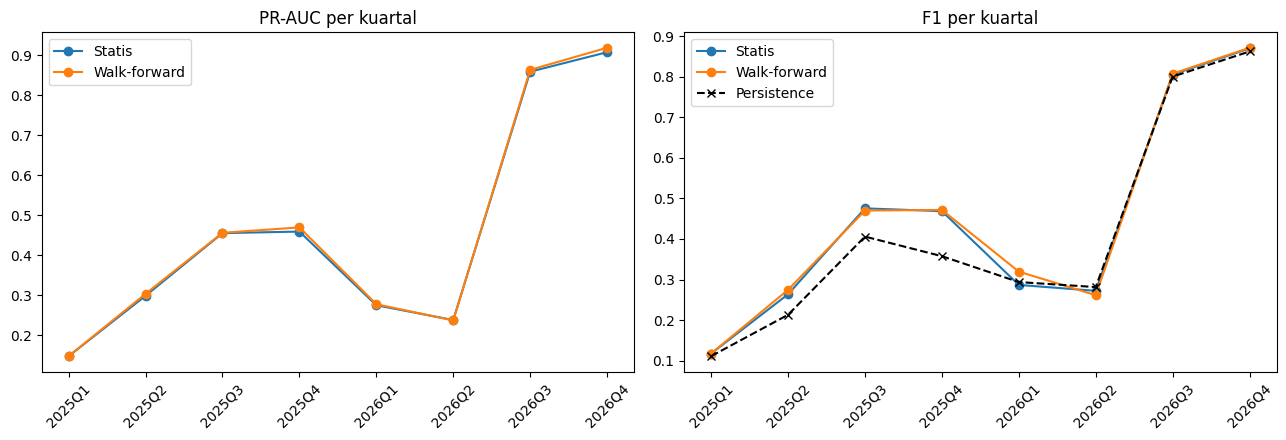

In [15]:
# ================= WALK-FORWARD =================
def metrik_blok(y, p, thr):
    if y.nunique() < 2:
        return dict(PR_AUC=np.nan, F1=np.nan, Recall=np.nan, Precision=np.nan)
    pred = (p >= thr).astype(int)
    return dict(PR_AUC=average_precision_score(y, p),
                F1=f1_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred, zero_division=0),
                Precision=precision_score(y, pred, zero_division=0))

pn["kuartal"] = pn["tanggal"].dt.to_period("Q")
kuartal_uji = sorted(pn.loc[pn["tanggal"] > T0, "kuartal"].unique())
THR_SV = THR["Soft Voting"]

def jalankan_wf():
    rows = []
    for q in kuartal_uji:
        # buang 1 hari terakhir sebelum kuartal uji (targetnya jatuh di kuartal uji)
        tr_q = pn[pn["tanggal"] < q.start_time - pd.Timedelta(days=1)]
        te_q = pn[pn["kuartal"] == q]
        yq = te_q["target"]

        rf_q, xgb_q = latih(tr_q[F].reset_index(drop=True),
                            tr_q["target"].reset_index(drop=True), SK_TERBAIK)
        p_wf = proba_ens(rf_q, xgb_q, te_q[F])         # dilatih ulang dengan data bertambah
        p_st = proba_ens(rf_f, xgb_f, te_q[F])         # model statis (dilatih sekali, <= 2024)
        f1_pers = (f1_score(yq, te_q["hs_hari_ini"], zero_division=0)
                   if yq.nunique() > 1 else np.nan)

        for mode, p, n in [("Walk-forward", p_wf, len(tr_q)), ("Statis", p_st, len(X_full))]:
            rows.append({"Kuartal": str(q), "Mode": mode, "n_train": n,
                         "n_positif": int(yq.sum()), "F1 persistence": f1_pers,
                         **metrik_blok(yq, p, THR_SV)})
    return pd.DataFrame(rows)

wf = cached("walkforward_v2", jalankan_wf)
print(wf.round(4))

# ringkasan selisih walk-forward vs statis
rg = wf.pivot(index="Kuartal", columns="Mode", values=["PR_AUC", "F1"])
sel = pd.DataFrame({
    "n_positif": wf[wf["Mode"] == "Statis"].set_index("Kuartal")["n_positif"],
    "Selisih PR-AUC (WF - statis)": rg[("PR_AUC", "Walk-forward")] - rg[("PR_AUC", "Statis")],
    "Selisih F1 (WF - statis)": rg[("F1", "Walk-forward")] - rg[("F1", "Statis")]})
print("\nSelisih walk-forward vs statis:")
print(sel.round(4))

# grafik
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for mode, d in wf.groupby("Mode"):
    ax[0].plot(d["Kuartal"], d["PR_AUC"], marker="o", label=mode)
    ax[1].plot(d["Kuartal"], d["F1"], marker="o", label=mode)
dp = wf[wf["Mode"] == "Statis"]
ax[1].plot(dp["Kuartal"], dp["F1 persistence"], "k--", marker="x", label="Persistence")
ax[0].set_title("PR-AUC per kuartal"); ax[1].set_title("F1 per kuartal")
for a in ax:
    a.legend(); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/walkforward_v2.png", dpi=200); plt.show()

# Tahap 12 Analisis galat dan interpretasi

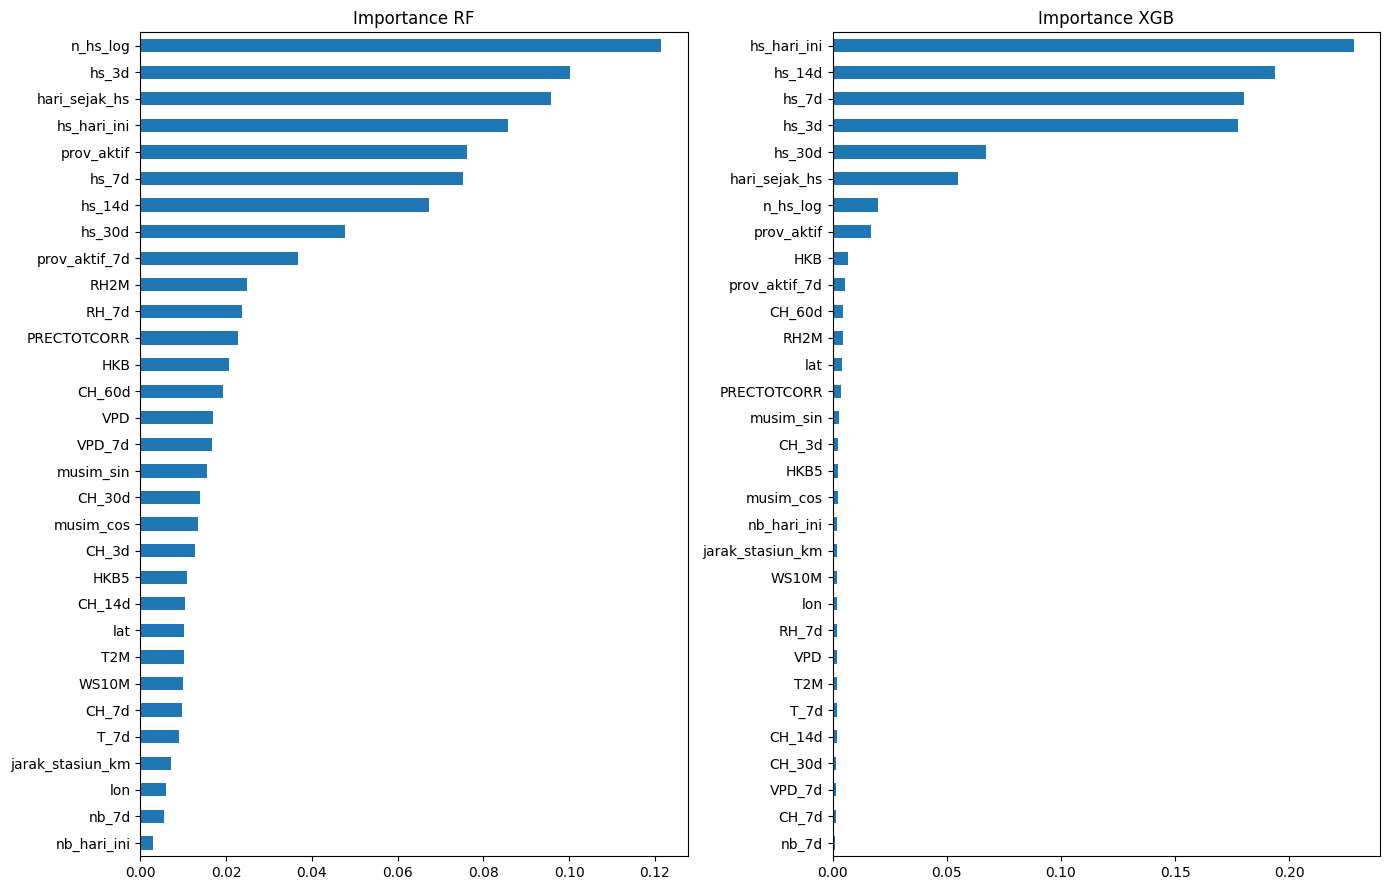

Per bulan:
         n_positif  n_alarm  precision  recall     F1     FP    FN
bulan                                                             
2025-01       12.0      0.0      0.000   0.000  0.000    0.0  12.0
2025-02       30.0     12.0      0.333   0.133  0.190    8.0  26.0
2025-03       12.0      2.0      0.000   0.000  0.000    2.0  12.0
2025-04       17.0      1.0      1.000   0.059  0.111    0.0  16.0
2025-05       61.0     35.0      0.429   0.246  0.312   20.0  46.0
2025-06       46.0     22.0      0.364   0.174  0.235   14.0  38.0
2025-07      122.0    117.0      0.487   0.467  0.477   60.0  65.0
2025-08       71.0     84.0      0.321   0.380  0.348   57.0  44.0
2025-09      115.0    101.0      0.604   0.530  0.565   40.0  54.0
2025-10      142.0    162.0      0.506   0.577  0.539   80.0  60.0
2025-11       27.0      9.0      0.000   0.000  0.000    9.0  27.0
2025-12        8.0      2.0      0.000   0.000  0.000    2.0   8.0
2026-01       88.0     85.0      0.424   0.409  0.4

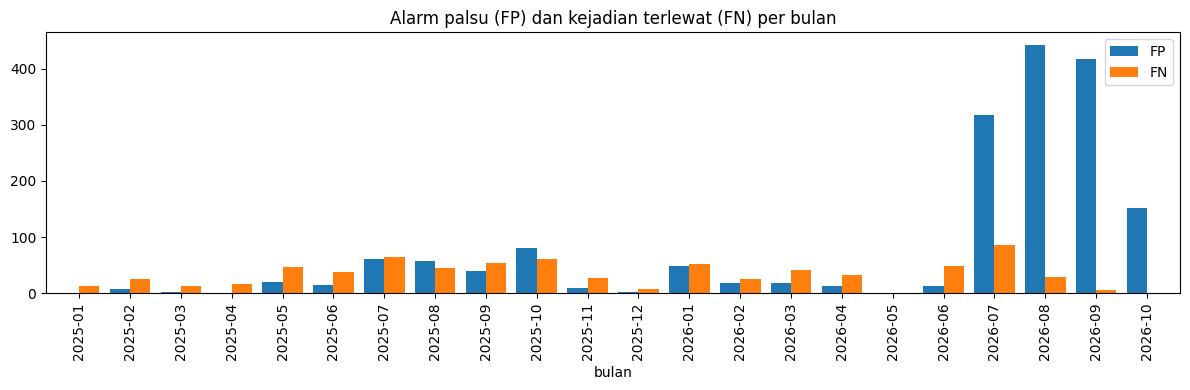


Alarm palsu (FP) total: 1733
  ada hotspot di zona itu dalam 7 hari terakhir : 94.5%
  ada hotspot di zona itu pada hari alarm       : 51.0%
Kejadian terlewat (FN) total: 727
  tanpa hotspot 7 hari terakhir (awal api baru) : 58.2%
  dengan hotspot 7 hari terakhir (kelanjutan)   : 41.8%

Trade-off threshold (test):
           precision  recall     F1  n_alarm  alarm per kejadian tertangkap
threshold                                                                  
0.10           0.540   0.892  0.673     7000                          1.852
0.15           0.611   0.858  0.714     5944                          1.636
0.20           0.661   0.834  0.737     5349                          1.514
0.21           0.669   0.828  0.740     5243                          1.495
0.30           0.737   0.776  0.756     4461                          1.358
0.40           0.812   0.685  0.743     3573                          1.232
0.50           0.859   0.573  0.687     2827                          1.165

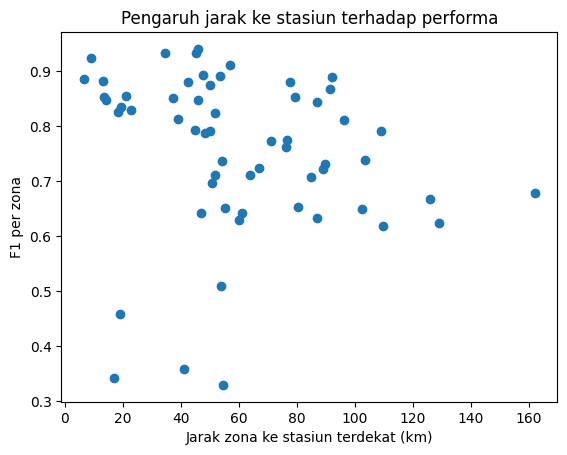

In [16]:
# ================= ANALISIS GALAT v2 =================
from scipy.stats import spearmanr

thr_f = THR["Soft Voting"]
err = te[["zona", "tanggal", "target", "hs_hari_ini", "hs_7d"]].copy()
err["p"] = P["Soft Voting"]
err["pred"] = (err["p"] >= thr_f).astype(int)
err["bulan"] = err["tanggal"].dt.to_period("M")

def ringkas(d):
    return pd.Series({
        "n_positif": d["target"].sum(), "n_alarm": d["pred"].sum(),
        "precision": precision_score(d["target"], d["pred"], zero_division=0),
        "recall": recall_score(d["target"], d["pred"], zero_division=0),
        "F1": f1_score(d["target"], d["pred"], zero_division=0),
        "FP": ((d["pred"] == 1) & (d["target"] == 0)).sum(),
        "FN": ((d["pred"] == 0) & (d["target"] == 1)).sum()})

# ---------- 1) feature importance ----------
fig, ax = plt.subplots(1, 2, figsize=(14, 9))
pd.Series(rf_f.feature_importances_, index=F).sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Importance RF")
pd.Series(xgb_f.feature_importances_, index=F).sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Importance XGB")
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/feature_importance.png", dpi=200); plt.show()

# ---------- 2) galat per bulan ----------
pb = err.groupby("bulan").apply(ringkas, include_groups=False)
print("Per bulan:"); print(pb.round(3))
pb[["FP", "FN"]].plot.bar(figsize=(12, 4), width=0.8)
plt.title("Alarm palsu (FP) dan kejadian terlewat (FN) per bulan")
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/galat_per_bulan.png", dpi=200); plt.show()

# ---------- 3) jenis galat: menguji penyebab FP dan FN ----------
fp = err[(err["pred"] == 1) & (err["target"] == 0)]
fn = err[(err["pred"] == 0) & (err["target"] == 1)]
print("\nAlarm palsu (FP) total:", len(fp))
print("  ada hotspot di zona itu dalam 7 hari terakhir : %.1f%%" % (100 * (fp["hs_7d"] > 0).mean()))
print("  ada hotspot di zona itu pada hari alarm       : %.1f%%" % (100 * (fp["hs_hari_ini"] == 1).mean()))
print("Kejadian terlewat (FN) total:", len(fn))
print("  tanpa hotspot 7 hari terakhir (awal api baru) : %.1f%%" % (100 * (fn["hs_7d"] == 0).mean()))
print("  dengan hotspot 7 hari terakhir (kelanjutan)   : %.1f%%" % (100 * (fn["hs_7d"] > 0).mean()))

# ---------- 4) trade-off threshold ----------
rows = []
for t in sorted(set([0.1, 0.15, 0.2, round(thr_f, 3), 0.3, 0.4, 0.5, 0.6, 0.7])):
    pr_ = (err["p"] >= t).astype(int)
    tp = int(((pr_ == 1) & (err["target"] == 1)).sum())
    rows.append({"threshold": t, "precision": precision_score(err["target"], pr_, zero_division=0),
                 "recall": recall_score(err["target"], pr_, zero_division=0),
                 "F1": f1_score(err["target"], pr_, zero_division=0),
                 "n_alarm": int(pr_.sum()), "alarm per kejadian tertangkap": pr_.sum() / max(tp, 1)})
print("\nTrade-off threshold (test):"); print(pd.DataFrame(rows).set_index("threshold").round(3))

# ---------- 5) galat per zona dan pengaruh jarak ke stasiun ----------
ez = err.groupby("zona").apply(ringkas, include_groups=False).join(zi[["jarak_stasiun_km"]])
print("\n10 zona dengan FN terbanyak:")
print(ez.sort_values("FN", ascending=False).head(10).round(3))
print("\n10 zona dengan FP terbanyak:")
print(ez.sort_values("FP", ascending=False).head(10).round(3))

ok = ez[ez["n_positif"] >= 20]
r, pv = spearmanr(ok["jarak_stasiun_km"], ok["F1"])
print(f"\nKorelasi Spearman jarak-stasiun vs F1 (n={len(ok)} zona): r={r:.2f}, p={pv:.3f}")
plt.scatter(ok["jarak_stasiun_km"], ok["F1"])
plt.xlabel("Jarak zona ke stasiun terdekat (km)"); plt.ylabel("F1 per zona")
plt.title("Pengaruh jarak ke stasiun terhadap performa")
plt.savefig(f"{SAVE_DIR}/jarak_stasiun_vs_f1.png", dpi=200); plt.show()